<a href="https://colab.research.google.com/github/naitsircm/Inverse-Problems-via-Convex-Optimisation/blob/main/sonic_blackbox_deblurring.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

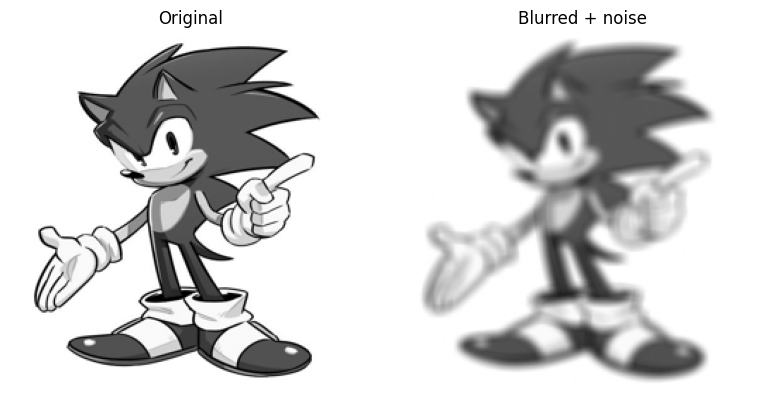

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from scipy.fft import dct, idct
from scipy.sparse.linalg import LinearOperator, cg

img = Image.open("sonic.jpg").resize((256, 256))
X_ref = np.asarray(ImageOps.grayscale(img), dtype=np.float64) / 255.0

def dct2(a):
    return dct(dct(a.T, norm="ortho").T, norm="ortho")

def idct2(a):
    return idct(idct(a.T, norm="ortho").T, norm="ortho")

def blackbox():
    s = 4
    size_filter = 9
    PSF = np.array([
        [np.exp(-0.5*((i-4)/s)**2 - 0.5*((j-4)/s)**2)
         for j in range(size_filter)]
        for i in range(size_filter)
    ], dtype=np.float64)
    PSF /= PSF.sum()

    def dctshift(PSF, center):
        m, n = PSF.shape
        i, j = center
        ell = min(i, m-i-1, j, n-j-1)
        PP = PSF[i-ell:i+ell+1, j-ell:j+ell+1]
        Z1 = np.diag(np.ones(ell+1), k=ell)
        Z2 = np.diag(np.ones(ell), k=ell+1)
        PP = (Z1 @ PP @ Z1.T + Z1 @ PP @ Z2.T
              + Z2 @ PP @ Z1.T + Z2 @ PP @ Z2.T)
        Ps = np.zeros_like(PSF)
        Ps[:2*ell+1, :2*ell+1] = PP
        return Ps

    Pbig = np.zeros_like(X_ref)
    Pbig[:size_filter, :size_filter] = PSF
    e1 = np.zeros_like(X_ref)
    e1[0, 0] = 1.0
    S = dct2(dctshift(Pbig, (4, 4))) / dct2(e1)

    def R(X):
        return idct2(S * dct2(X))
    return R

R = blackbox()

rng = np.random.default_rng(10)
noise = rng.normal(0, 0.5/255.0, size=X_ref.shape)
X_blur = R(X_ref) + noise

fig, ax = plt.subplots(1,2,figsize=(8,4))
ax[0].imshow(X_ref,cmap="gray",vmin=0,vmax=1); ax[0].set_title("Original")
ax[1].imshow(X_blur,cmap="gray",vmin=0,vmax=1); ax[1].set_title("Blurred + noise")
for a in ax: a.axis("off")
plt.tight_layout()

In [31]:
# Forward differences and exact adjoint
def grad(x):
    G = np.zeros((2, *x.shape), dtype=x.dtype)
    G[0, :, :-1] = x[:, 1:] - x[:, :-1]
    G[1, :-1, :] = x[1:, :] - x[:-1, :]
    return G

def grad_T(y):
    out = np.zeros_like(y[0])
    out[:, :-1] -= y[0, :, :-1]
    out[:, 1:]  += y[0, :, :-1]
    out[:-1, :] -= y[1, :-1, :]
    out[1:, :]  += y[1, :-1, :]
    return out

def soft_threshold(v, t):
    return np.sign(v) * np.maximum(np.abs(v)-t, 0)

def objective(x, lam):
    return 0.5*lam*np.sum((R(x)-X_blur)**2) + np.sum(np.abs(grad(x)))

# The blackbox is diagonal in an orthonormal DCT basis.
# Estimate ||R||^2 from the same response implicit in R, via power iteration.
def power_norm_sq(apply, shape, n_iter=35):
    v=np.random.default_rng(0).standard_normal(shape)
    v/=np.linalg.norm(v)
    for _ in range(n_iter):
        w=apply(v)
        nw=np.linalg.norm(w)
        if nw == 0: return 0.0
        v=w/nw
    return float(np.linalg.norm(apply(v)))

R_norm_sq = power_norm_sq(lambda x: R(R(x)), X_ref.shape)
print("Estimated ||R||^2 =", R_norm_sq)

rng=np.random.default_rng(2)
u=rng.standard_normal(X_ref.shape); v=rng.standard_normal((2,*X_ref.shape))
lhs=np.vdot(grad(u),v); rhs=np.vdot(u,grad_T(v))
print("Gradient-adjoint relative error:",
      abs(lhs-rhs)/(abs(lhs)+1e-12))

Estimated ||R||^2 = 0.9904179383661244
Gradient-adjoint relative error: 1.9084068176745666e-15


In [32]:
def primal_dual(lam=1700, maxit=2000, tol=1e-6):
    # h(x)=lam/2 ||Rx-b||^2, g(Kx)=||Kx||_1.
    L = lam * R_norm_sq
    # CP condition: tau*L/2 + tau*sigma*||K||^2 < 1; ||grad||^2 <= 8.
    tau = 5*1e-4
    sigma = 1e-6
    x = X_blur.copy()
    xbar = x.copy()
    y = np.zeros((2,*x.shape))
    hist=[]
    for k in range(maxit):
        x_new = x - tau*(lam*R(R(x)-X_blur) + grad_T(y))
        y_new = np.clip(y + sigma*grad(xbar), -1, 1)
        rel=np.linalg.norm(x_new-x)/(np.linalg.norm(x)+1e-12)
        xbar=2*x_new-x
        x,y=x_new,y_new
        hist.append(objective(x,lam))
        if rel<tol: break
    return np.clip(x,0,1), np.asarray(hist), k+1, (tau,sigma)

lam = 1700
X_pd, hist_pd, it_pd, steps = primal_dual(lam=lam)
print(f"Primal-Dual: {it_pd} iterations, tau={steps[0]:.3g}, sigma={steps[1]:.3g}")

Primal-Dual: 2000 iterations, tau=0.0005, sigma=1e-06


In [33]:
def admm(lam=20400, rho=40.0, maxit=300, cg_maxit=500, tol=1e-6):
    shape=X_blur.shape
    n=X_blur.size
    def matvec(v):
        x=v.reshape(shape)
        return (lam*R(R(x)) + rho*grad_T(grad(x))).ravel()
    A=LinearOperator((n,n),matvec=matvec,dtype=np.float64)
    rhs_data=lam*R(X_blur)
    x=X_blur.copy()
    y=grad(x)
    u=np.zeros_like(y)  # scaled dual
    hist=[]
    for k in range(maxit):
        rhs=(rhs_data + rho*grad_T(y-u)).ravel()
        xvec, info=cg(A,rhs,x0=x.ravel(),maxiter=cg_maxit,rtol=1e-6,atol=0)
        if info<0:
            raise RuntimeError("CG failed")
        x_new=xvec.reshape(shape)
        gx=grad(x_new)
        y_new=soft_threshold(gx+u,1.0/rho)
        u_new=u+gx-y_new
        rel=np.linalg.norm(x_new-x)/(np.linalg.norm(x)+1e-12)
        x,y,u=x_new,y_new,u_new
        hist.append(objective(x,lam))
        if rel<tol: break
    return np.clip(x,0,1),np.asarray(hist),k+1

X_admm,hist_admm,it_admm=admm()
print(f"ADMM: {it_admm} iterations")

ADMM: 131 iterations


Blurred MSE: 0.0185722
Primal-Dual MSE: 0.0056194
ADMM MSE: 0.00414599


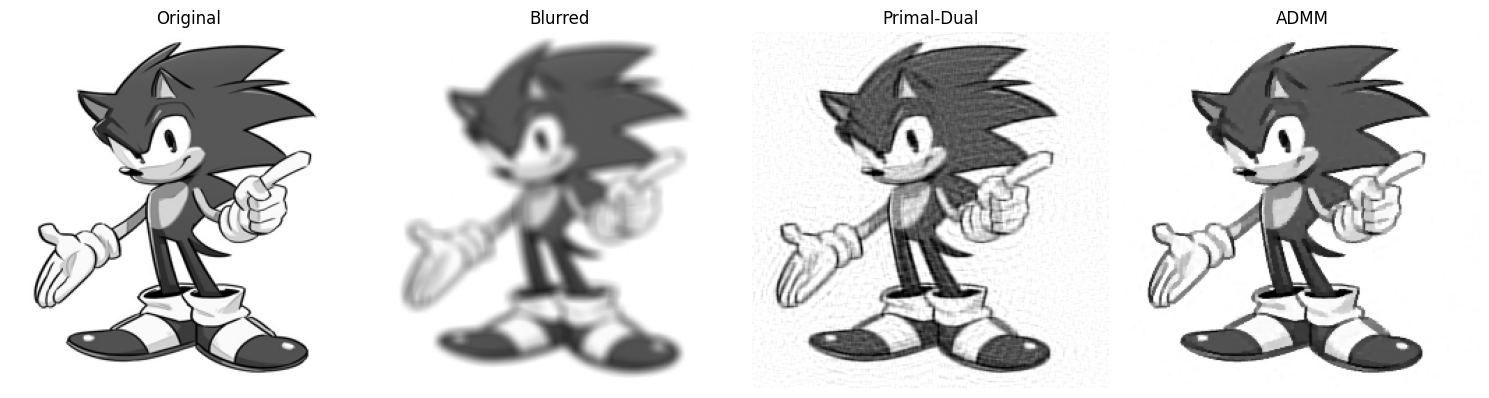

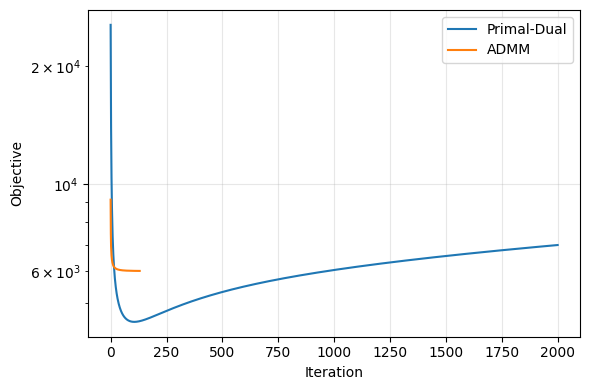

In [34]:
fig,ax=plt.subplots(1,4,figsize=(15,4))
for a,im,title in zip(ax,[X_ref,X_blur,X_pd,X_admm],
                      ["Original","Blurred","Primal-Dual","ADMM"]):
    a.imshow(im,cmap="gray",vmin=0,vmax=1); a.set_title(title); a.axis("off")
plt.tight_layout()

plt.figure(figsize=(6,4))
plt.semilogy(hist_pd,label="Primal-Dual")
plt.semilogy(hist_admm,label="ADMM")
plt.xlabel("Iteration"); plt.ylabel("Objective"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout()

mse=lambda a,b: np.mean((a-b)**2)
print(f"Blurred MSE: {mse(X_blur,X_ref):.6g}")
print(f"Primal-Dual MSE: {mse(X_pd,X_ref):.6g}")
print(f"ADMM MSE: {mse(X_admm,X_ref):.6g}")